# Recurrent translation with additive attention

Can a small translation model generalize to held-out sentence combinations?

I train on a controlled English-Italian parallel corpus and evaluate autoregressive predictions separately from teacher-forced token loss. An optional TSV input supports a real parallel corpus with the same pipeline.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import copy
import inspect
import json
import os
from pathlib import Path
import sys
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / "src"))
from nlp_portfolio.translation import (
    PAD,
    Vocabulary,
    controlled_parallel_corpus,
    read_parallel_tsv,
    encode_pairs,
    AttentionTranslator,
)

random.seed(1031)
np.random.seed(1031)
torch.manual_seed(1031)
torch.set_num_threads(2)
QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 35 if QUICK else 150
output = root / "figures" / "14_seq2seq_translation"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'epochs': 150, 'seed': 1031}


## Parallel corpus and vocabulary

The default data are 192 grammar-generated sentence pairs. They are synthetic language examples, so measured scores do not describe natural translation quality. Splits separate sentence pairs, and each vocabulary is fitted on training text only. `PARALLEL_TSV` can point to a UTF-8 file with one source and one target sentence per line, separated by a tab.

In [5]:
corpus_path = os.environ.get("PARALLEL_TSV")
pairs = (
    read_parallel_tsv(Path(corpus_path))
    if corpus_path
    else controlled_parallel_corpus()
)
development, test_ids = train_test_split(
    np.arange(len(pairs)), test_size=0.2, random_state=1031
)
train_ids, validation_ids = train_test_split(
    development, test_size=0.25, random_state=1031
)
train_pairs = [pairs[index] for index in train_ids]
validation_pairs = [pairs[index] for index in validation_ids]
test_pairs = [pairs[index] for index in test_ids]
source_vocabulary = Vocabulary([pair[0] for pair in train_pairs])
target_vocabulary = Vocabulary([pair[1] for pair in train_pairs])
vocabularies = (source_vocabulary, target_vocabulary)
datasets = [
    encode_pairs(partition, vocabularies)
    for partition in [train_pairs, validation_pairs, test_pairs]
]
train_data, validation_data, test_data = datasets
train_loader = DataLoader(
    TensorDataset(train_data.source, train_data.target),
    24,
    shuffle=True,
    generator=torch.Generator().manual_seed(1031),
)
print(
    {
        "train": len(train_pairs),
        "validation": len(validation_pairs),
        "test": len(test_pairs),
    }
)
print(train_pairs[:4])
print(len(source_vocabulary), len(target_vocabulary))
assert len(set(train_pairs) & set(test_pairs)) == 0

{'train': 114, 'validation': 39, 'test': 39}
[('i read the protocol in the laboratory', 'io leggo il protocollo in laboratorio'), ('they observe the tissue today', 'loro osservano il tessuto oggi'), ('they observe the image carefully', "loro osservano l'immagine attentamente"), ('we read the result in the laboratory', 'noi leggiamo il risultato in laboratorio')]
28 36


## Model and tensor shapes

The encoder reads packed source sequences, keeping its final state independent of padding. Additive attention masks padded source positions before softmax. At each decoder step, the current word embedding and attended context enter a GRU; the decoder predicts the next token.

In [7]:
model = AttentionTranslator(len(source_vocabulary), len(target_vocabulary))
print(inspect.getsource(AttentionTranslator))
probe = model(train_data.source[:3], train_data.target[:3, :-1])
assert probe.shape == (3, train_data.target.shape[1] - 1, len(target_vocabulary))
print(probe.shape, sum(parameter.numel() for parameter in model.parameters()))

class AttentionTranslator(nn.Module):
    def __init__(self, source_size, target_size, hidden=48):
        super().__init__()
        self.source_embedding = nn.Embedding(source_size, hidden, padding_idx=PAD)
        self.target_embedding = nn.Embedding(target_size, hidden, padding_idx=PAD)
        self.encoder = nn.GRU(hidden, hidden, batch_first=True)
        self.attention = AdditiveAttention(hidden)
        self.decoder = nn.GRU(2 * hidden, hidden, batch_first=True)
        self.output = nn.Linear(2 * hidden, target_size)

    def encode(self, source):
        lengths = source.ne(PAD).sum(-1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(
            self.source_embedding(source), lengths, batch_first=True, enforce_sorted=False
        )
        encoded, hidden = self.encoder(packed)
        encoded, _ = nn.utils.rnn.pad_packed_sequence(encoded, batch_first=True, total_length=source.shape[1])
        return encoded, hidden, source.eq(PAD)

    def decode_step(self, token

## Teacher forcing and training

The decoder input excludes the last target token, while labels exclude BOS. Padding contributes no loss. Epoch losses divide the sum of token losses by the count of non-padding labels, so short batches and padded sentences receive appropriate weight. Validation chooses the checkpoint using teacher-forced NLL.

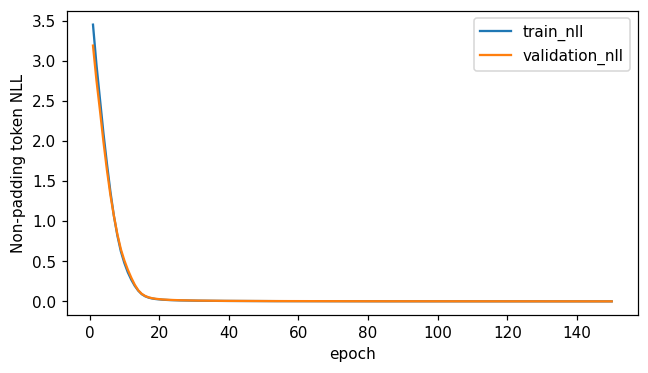

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
history, best_loss, best_weights = [], float("inf"), None
for epoch in range(EPOCHS):
    model.train()
    total, count = 0.0, 0
    for source, target in train_loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(source, target[:, :-1])
        token_sum = F.cross_entropy(
            logits.flatten(0, 1),
            target[:, 1:].flatten(),
            ignore_index=PAD,
            reduction="sum",
        )
        token_count = int(target[:, 1:].ne(PAD).sum())
        (token_sum / token_count).backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1)
        optimizer.step()
        total += float(token_sum.detach())
        count += token_count
    model.eval()
    with torch.inference_mode():
        logits = model(validation_data.source, validation_data.target[:, :-1])
        token_sum = F.cross_entropy(
            logits.flatten(0, 1),
            validation_data.target[:, 1:].flatten(),
            ignore_index=PAD,
            reduction="sum",
        )
        validation_loss = float(token_sum / validation_data.target[:, 1:].ne(PAD).sum())
    history.append(
        {
            "epoch": epoch + 1,
            "train_nll": total / count,
            "validation_nll": validation_loss,
        }
    )
    if validation_loss < best_loss:
        best_loss, best_weights = validation_loss, copy.deepcopy(model.state_dict())
model.load_state_dict(best_weights)
model.eval()
pd.DataFrame(history).plot(
    x="epoch", y=["train_nll", "validation_nll"], figsize=(6, 3.5)
)
plt.ylabel("Non-padding token NLL")
plt.tight_layout()
plt.savefig(output / "loss.png", dpi=140)
plt.show()

## Padding and attention check

Appending source padding must not change a real sentence's logits. The packed GRU and attention mask enforce this property. The attention map below uses teacher-forced decoder prefixes, which differ from a generated translation if earlier predictions are wrong.

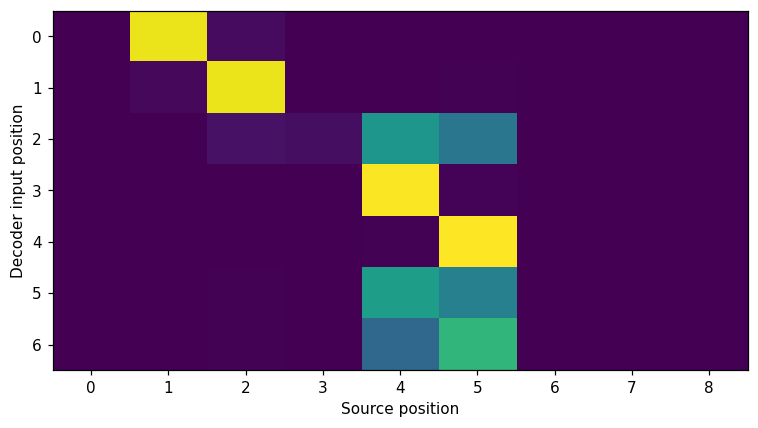

In [11]:
source = test_data.source[:1]
target = test_data.target[:1, :-1]
with torch.inference_mode():
    original = model(source, target)
    padded = model(F.pad(source, (0, 4), value=PAD), target)
    encoded, hidden, padding = model.encode(source)
    weights = []
    for token in target.unbind(1):
        _, hidden, attention = model.decode_step(token, hidden, encoded, padding)
        weights.append(attention[0])
assert torch.allclose(original, padded, atol=1e-5)
attention_map = torch.stack(weights)
assert torch.allclose(attention_map.sum(-1), torch.ones(len(weights)), atol=1e-6)
fig, axis = plt.subplots(figsize=(7, 4))
axis.imshow(attention_map.numpy(), aspect="auto", cmap="viridis")
axis.set(xlabel="Source position", ylabel="Decoder input position")
fig.tight_layout()
fig.savefig(output / "attention.png", dpi=140)
plt.show()

## Autoregressive test

Greedy generation begins with BOS and stops at EOS or a maximum length. Exact match compares decoded strings with references. Teacher-forced token accuracy is reported separately because it supplies correct preceding tokens and can hide generation errors. A most-frequent-target baseline has no source conditioning.

In [13]:
from collections import Counter

generated = model.generate(test_data.source, max_tokens=20)
predictions = [target_vocabulary.decode(sequence.tolist()) for sequence in generated]
references = [pair[1] for pair in test_pairs]
exact_match = float(
    np.mean(
        [
            prediction == reference
            for prediction, reference in zip(predictions, references)
        ]
    )
)
with torch.inference_mode():
    logits = model(test_data.source, test_data.target[:, :-1])
labels = test_data.target[:, 1:]
valid = labels.ne(PAD)
token_accuracy = float(logits.argmax(-1)[valid].eq(labels[valid]).float().mean())
baseline = Counter(pair[1] for pair in train_pairs).most_common(1)[0][0]
baseline_exact = float(np.mean([reference == baseline for reference in references]))
examples = pd.DataFrame(
    {
        "source": [pair[0] for pair in test_pairs],
        "reference": references,
        "prediction": predictions,
    }
)
print(examples.head(12).to_string(index=False))
examples.to_csv(root / "results" / f"{output.name}_predictions.csv", index=False)
results = {
    "autoregressive_exact_match": exact_match,
    "teacher_forced_token_accuracy": token_accuracy,
    "constant_baseline_exact_match": baseline_exact,
    "best_validation_nll": best_loss,
    "synthetic_corpus": corpus_path is None,
    "training_pairs": len(train_pairs),
    "test_pairs": len(test_pairs),
}
print(results)

                           source                               reference                              prediction
  you read the protocol carefully     tu leggi il protocollo attentamente     tu leggi il protocollo attentamente
       we read the protocol again     noi leggiamo il protocollo di nuovo     noi leggiamo il protocollo di nuovo
    we read the article carefully    noi leggiamo l'articolo attentamente    noi leggiamo l'articolo attentamente
      i read the report carefully       io leggo il rapporto attentamente       io leggo il rapporto attentamente
they observe the sample carefully loro osservano il campione attentamente loro osservano il campione attentamente
   you observe the cell carefully      tu osservi la cellula attentamente      tu osservi la cellula attentamente
  we observe the experiment again   noi osserviamo l'esperimento di nuovo   noi osserviamo l'esperimento di nuovo
  we observe the experiment today       noi osserviamo l'esperimento oggi       noi osse

## Reading the result

The controlled grammar tests held-out combinations of familiar vocabulary. It does not evaluate unrestricted translation, unseen domains or fluent handling of arbitrary sentences. The autoregressive score is the relevant generation check; teacher-forced accuracy measures a different prediction setting.

In [15]:
result_path = root / "results" / "14_seq2seq_translation.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/14_seq2seq_translation.json


## Next experiment

Use a real parallel TSV with documented provenance and separate near-duplicate sentence groups before splitting. Add corpus BLEU or chrF, inspect unknown-token rates and retain example translations for errors.

## Sources

UniPd Machine Learning for Human Data: uploaded Lab_nn and Labs 1 to 7, plus the [course data folder](https://drive.google.com/drive/folders/14xwb6leBeD3QMZH6wnnIIOi63D1D8xmS). Lab_seq2seq and Lab_transformers. [HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week08_transformers.

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.